# Tech Challenge Fase 2 — Classificando a qualidade de vinhos
## Notebook 02 · Pré-processamento, modelagem, avaliação e interpretação

Este notebook parte das decisões tomadas na EDA (notebook 01) e responde às etapas 3 a 6 do desafio.

**Roteiro**
1. Preparação dos dados e divisão treino/teste
2. Pré-processamento dentro de um pipeline (sem vazamento)
3. Linha de base: o que a acurácia esconde
4. Treinamento e ajuste de 5 modelos com validação cruzada
5. Comparação robusta (validação cruzada repetida)
6. Avaliação no conjunto de teste
7. Escolha do limiar de decisão
8. Interpretação: o que mais influencia a qualidade
9. Implicações para o processo de produção
10. Conclusões e limitações

In [1]:
# Configuração do ambiente — funciona no Google Colab e localmente (Jupyter/VS Code)
import sys
from pathlib import Path

EM_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/igorsycko/postech15dtat-tech-challenge-2-wine.git"

if EM_COLAB:
    REPO_DIR = "/content/postech15dtat-tech-challenge-2-wine"
    if not Path(REPO_DIR).exists():
        !git clone -q {REPO_URL} {REPO_DIR}
    %cd {REPO_DIR}
    !pip install -q -r requirements.txt

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
print("Raiz do projeto:", ROOT)

Raiz do projeto: /content/postech15dtat-tech-challenge-2-wine


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, classification_report,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate, train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

from src.config import FEATURES, TARGET, RANDOM_STATE, TEST_SIZE, RESULTS_DIR, label
from src.data import load_dataset
from src.preprocessing import WineFeatureEngineer, LogTransformer, SKEWED_FEATURES
from src.modeling import build_models, tune_models, cv_splitter, MODEL_NAMES, SCORING
from src.evaluation import (classification_metrics, oof_probabilities, best_f1_threshold,
                            threshold_table, format_metrics)
from src import visualization as viz

viz.set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

## 1. Preparação dos dados e divisão treino/teste

Aplicamos as decisões da EDA: remover `id`, criar o alvo `alta_qualidade` (nota ≥ 7) e remover as 125 linhas
repetidas. A nota original (`quality`) **não entra** como variável explicativa — ela é a origem do alvo
(usá-la seria vazamento).

Divisão **80% treino / 20% teste, estratificada** pelo alvo (mantém ~13,5% de vinhos bons nas duas partes) e com
semente fixa para reprodutibilidade. O teste fica guardado e só é usado na seção 6.

In [3]:
df = load_dataset()                    # já sem id, com alvo e sem duplicatas
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

pd.DataFrame({
    "linhas": [len(X_train), len(X_test)],
    "vinhos de alta qualidade": [int(y_train.sum()), int(y_test.sum())],
    "% alta qualidade": [y_train.mean(), y_test.mean()],
}, index=["treino", "teste"]).style.format({"% alta qualidade": "{:.1%}"})

,linhas,vinhos de alta qualidade,% alta qualidade
treino,814,110,13.5%
teste,204,27,13.2%


O conjunto de teste tem **apenas 27 vinhos de alta qualidade**. Isso é importante para interpretar os resultados:
um acerto a mais ou a menos muda o recall em ~3,7 pontos. Por isso a **escolha dos modelos é feita pela validação
cruzada no treino** (5 dobras estratificadas, e depois 5×3 repetições), e o teste serve como confirmação final.

## 2. Pré-processamento dentro de um pipeline

Todas as transformações ficam **dentro de um `Pipeline`**, de modo que, em cada dobra da validação cruzada e no
treino final, elas são ajustadas apenas com os dados de treino — o teste nunca "vaza" para o ajuste
(cuidado reforçado nas aulas: `fit` só no treino, `transform` no teste).

| Etapa | O que faz | Por quê (evidência da EDA) | Modelos |
|---|---|---|---|
| `WineFeatureEngineer` | Cria acidez total, proporção SO₂ livre/total, SO₂ combinado e álcool × sulfatos | Resumem relações químicas encontradas (SO₂ livre ⊂ total; álcool e sulfatos são os maiores sinais positivos) | todos (testado ligado/desligado) |
| `LogTransformer` | log1p em açúcar residual, cloretos, SO₂ livre, SO₂ total e sulfatos | Assimetria forte (até 5,9) e outliers reais que queremos manter | KNN, SVM, Regressão Logística |
| `StandardScaler` | Padronização z-score | Escalas muito diferentes; modelos de distância/coeficiente exigem | KNN, SVM, Regressão Logística |
| Balanceamento | `class_weight="balanced"` (LR, SVM, árvore, RF) ou `RandomOverSampler` (KNN) | 13,5% de positivos; aplicado **só no treino** | todos |

Árvores e Random Forest não precisam de escala nem de log (dividem os dados por limiares, então são robustas a
outliers e a diferenças de unidade).

Não há dados faltantes (seção 3 da EDA), portanto não há etapa de imputação.

In [4]:
# Visualização do efeito das etapas em 3 amostras do treino (apenas ilustração)
amostra = X_train.head(3)
fe = WineFeatureEngineer().fit(X_train)
com_features = fe.transform(amostra)
com_log = LogTransformer().fit(com_features).transform(com_features)
print("Variáveis criadas:")
display(com_features[["total_acidity", "free_so2_ratio", "bound_sulfur_dioxide", "alcohol_x_sulphates"]]
        .rename(columns=label).round(3))
print("Efeito do log1p nas variáveis assimétricas:")
display(pd.concat([com_features[SKEWED_FEATURES].add_suffix(" (original)"),
                   com_log[SKEWED_FEATURES].add_suffix(" (log1p)")], axis=1).round(3).T)

Variáveis criadas:


,Acidez total,Proporção SO₂ livre/total,SO₂ combinado,Álcool × sulfatos
814,7.42,0.500,18.0,6.104
628,9.39,0.481,14.0,9.828
883,7.90,0.250,18.0,9.758


Efeito do log1p nas variáveis assimétricas:


,814,628,883
residual_sugar (original),2.300,2.050,2.000
chlorides (original),0.071,0.063,0.052
free_sulfur_dioxide (original),18.000,13.000,6.000
total_sulfur_dioxide (original),36.000,27.000,24.000
sulphates (original),0.560,0.840,0.820
residual_sugar (log1p),1.194,1.115,1.099
chlorides (log1p),0.069,0.061,0.051
free_sulfur_dioxide (log1p),2.944,2.639,1.946
total_sulfur_dioxide (log1p),3.611,3.332,3.219
sulphates (log1p),0.445,0.610,0.599


## 3. Linha de base: o que a acurácia esconde

Antes de treinar modelos de verdade, medimos dois "modelos bobos". Se um modelo real não for muito melhor que
eles, ele não aprendeu nada útil.

In [5]:
baselines = {
    "Sempre 'baixa/média'": DummyClassifier(strategy="most_frequent"),
    "Sorteio na proporção das classes": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
}
linhas = []
for nome, modelo in baselines.items():
    res = cross_validate(modelo, X_train, y_train, cv=cv_splitter(),
                         scoring={k: SCORING[k] for k in ["accuracy", "f1", "recall", "precision"]})
    linhas.append({"modelo": nome, **{k: res[f"test_{k}"].mean() for k in ["accuracy", "f1", "recall", "precision"]}})
pd.DataFrame(linhas).round(3)

,modelo,accuracy,f1,recall,precision
0,Sempre 'baixa/média',0.865,0.0,0.0,0.0
1,Sorteio na proporção das classes,0.757,0.1,0.1,0.1


O modelo que **sempre responde "baixa/média" tem ~86% de acurácia e F1 = 0** — não identifica nenhum vinho bom.
Isso confirma a decisão da EDA: **acurácia não é a métrica certa**. A referência a superar é um F1 ≈ 0,10 (sorteio).

## 4. Treinamento e ajuste de 5 modelos

Treinamos cinco algoritmos estudados na disciplina, de famílias diferentes:

| Modelo | Família | Por que testar |
|---|---|---|
| Regressão Logística | Linear / probabilístico | Referência interpretável (coeficientes) |
| KNN | Baseado em distância | Captura vizinhanças locais |
| SVM (kernel RBF) | Margem máxima | Fronteiras não lineares, bom em bases pequenas |
| Árvore de Decisão | Regras | Fácil de explicar a não técnicos |
| Random Forest | Ensemble de árvores | Robusta a outliers e interações |

Cada um passa por um **GridSearchCV** com **validação cruzada estratificada de 5 dobras**. O critério de escolha
dos hiperparâmetros é o **F1 da classe "alta"**; também registramos recall, precisão, ROC-AUC, PR-AUC e acurácia.

In [6]:
modelos = build_models()
for nome, (pipe, grade) in modelos.items():
    n = int(np.prod([len(v) for v in grade.values()]))
    print(f"{MODEL_NAMES[nome]:<22} etapas: {[s[0] for s in pipe.steps]} | {n} combinações")

Regressão Logística    etapas: ['features', 'log', 'scaler', 'model'] | 8 combinações
KNN                    etapas: ['features', 'log', 'scaler', 'oversample', 'model'] | 20 combinações
SVM (kernel RBF)       etapas: ['features', 'log', 'scaler', 'model'] | 12 combinações
Árvore de Decisão      etapas: ['features', 'model'] | 30 combinações
Random Forest          etapas: ['features', 'model'] | 18 combinações


In [7]:
# Ajuste de todos os modelos (leva ~1 a 3 minutos; a Random Forest é a mais demorada)
buscas, resumo_cv = tune_models(X_train, y_train, modelos)

Regressão Logística    F1 CV = 0.529 ± 0.032 | ROC-AUC = 0.884 | 2.1s


KNN                    F1 CV = 0.491 ± 0.047 | ROC-AUC = 0.865 | 4.1s


SVM (kernel RBF)       F1 CV = 0.528 ± 0.035 | ROC-AUC = 0.867 | 2.6s


Árvore de Decisão      F1 CV = 0.483 ± 0.035 | ROC-AUC = 0.801 | 2.5s


Random Forest          F1 CV = 0.549 ± 0.084 | ROC-AUC = 0.882 | 52.7s


In [8]:
cols = ["modelo", "cv_f1", "cv_f1_dp", "cv_recall", "cv_precision", "cv_roc_auc", "cv_pr_auc", "cv_accuracy",
        "treino_f1", "melhores_parametros"]
tabela_cv = resumo_cv[cols].copy()
tabela_cv.to_csv(RESULTS_DIR / "metricas_validacao_cruzada.csv", index=False)
format_metrics(tabela_cv)

,modelo,cv_f1,cv_f1_dp,cv_recall,cv_precision,cv_roc_auc,cv_pr_auc,cv_accuracy,treino_f1,melhores_parametros
0,Random Forest,0.549,0.084,0.600,0.508,0.882,0.580,0.869,0.840,"{'model__max_depth': 8, 'model__max_features':..."
1,Regressão Logística,0.529,0.032,0.827,0.389,0.884,0.575,0.801,0.530,"{'features__add_features': False, 'model__C': ..."
2,SVM (kernel RBF),0.528,0.035,0.727,0.417,0.867,0.554,0.824,0.703,"{'model__C': 1, 'model__gamma': 0.1}"
3,KNN,0.491,0.047,0.755,0.365,0.865,0.552,0.789,1.000,"{'model__metric': 'manhattan', 'model__n_neigh..."
4,Árvore de Decisão,0.483,0.035,0.782,0.350,0.801,0.426,0.774,0.635,"{'model__criterion': 'entropy', 'model__max_de..."


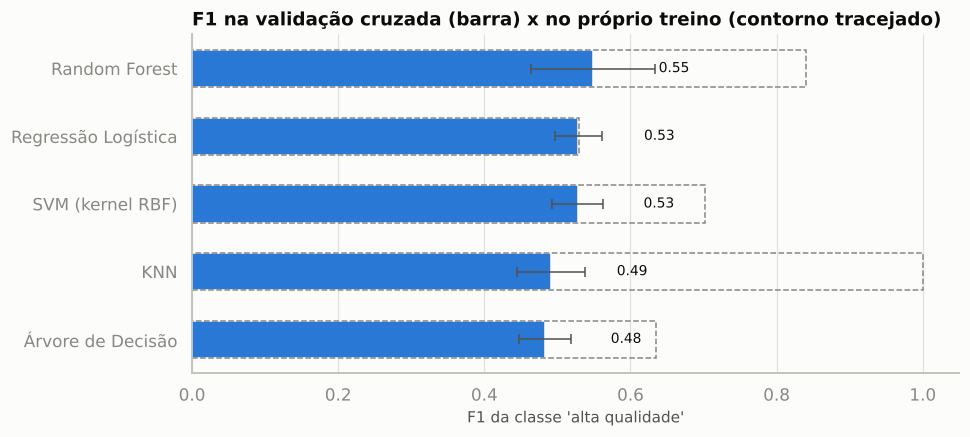

In [9]:
fig, ax = plt.subplots(figsize=(9, 4))
ordem = resumo_cv.sort_values("cv_f1")
ax.barh(ordem["modelo"], ordem["cv_f1"], xerr=ordem["cv_f1_dp"], color=viz.COLOR_HIGH, height=0.55,
        error_kw={"ecolor": viz.INK_2, "elinewidth": 1, "capsize": 3})
ax.barh(ordem["modelo"], ordem["treino_f1"], color="none", edgecolor=viz.MUTED, height=0.55,
        linestyle="--", linewidth=1)
for i, (cv, tr) in enumerate(zip(ordem["cv_f1"], ordem["treino_f1"])):
    ax.text(cv + 0.09, i, f"{cv:.2f}", va="center", fontsize=9, color=viz.INK)
ax.set_xlim(0, 1.05)
ax.set_xlabel("F1 da classe 'alta qualidade'")
ax.set_title("F1 na validação cruzada (barra) x no próprio treino (contorno tracejado)", loc="left")
ax.grid(axis="y", visible=False)
viz.save_fig(fig, "10_f1_validacao_cruzada")
plt.show()

**Leitura.**
- Todos os modelos superam com folga as linhas de base (F1 de 0,48 a 0,55 contra 0,10 do sorteio) e têm ROC-AUC
  entre 0,80 e 0,88 — há sinal real nas variáveis químicas.
- **Random Forest** tem o maior F1 médio (0,55), mas também a **maior variação entre dobras** (±0,08).
  **Regressão Logística** e **SVM** vêm logo atrás (0,53) com variação menor.
- **Sobreajuste:** a distância entre o F1 no treino (contorno) e na validação mostra que KNN (F1 de treino = 1,0,
  efeito dos pesos por distância), Random Forest (0,84) e SVM decoram parte do treino; a Regressão Logística
  praticamente não sobreajusta (0,53 x 0,53).
- **Feature engineering:** na Regressão Logística, a busca preferiu *não* usar as variáveis criadas
  (`features__add_features = False`) — elas não trouxeram ganho além das originais transformadas por log. Testamos
  o mesmo para a Random Forest abaixo.
- Diferenças de 1 a 2 pontos de F1 estão dentro do desvio-padrão: como lembrado nas aulas, nesses casos os
  modelos são **estatisticamente equivalentes** — a próxima seção usa repetições para separar melhor.

In [10]:
# Efeito das novas variáveis na Random Forest e na Regressão Logística (mesmos hiperparâmetros, com x sem)
linhas = []
for nome in ["rf", "logreg"]:
    for flag in [False, True]:
        est = buscas[nome].best_estimator_.set_params(features__add_features=flag)
        res = cross_validate(est, X_train, y_train, cv=cv_splitter(), scoring=["f1", "roc_auc"], n_jobs=-1)
        linhas.append({"modelo": MODEL_NAMES[nome], "com novas variáveis": flag,
                       "F1 (CV)": res["test_f1"].mean(), "ROC-AUC (CV)": res["test_roc_auc"].mean()})
    buscas[nome].best_estimator_.set_params(features__add_features=buscas[nome].best_params_.get(
        "features__add_features", True))
pd.DataFrame(linhas).round(3)

,modelo,com novas variáveis,F1 (CV),ROC-AUC (CV)
0,Random Forest,False,0.527,0.874
1,Random Forest,True,0.549,0.882
2,Regressão Logística,False,0.529,0.884
3,Regressão Logística,True,0.527,0.884


As variáveis criadas mudam o desempenho em poucos centésimos — dentro da variação entre dobras. Mantemos a etapa
no pipeline (é barata e tem significado enológico), mas **o ganho de desempenho vem principalmente das variáveis
originais**, especialmente de álcool, acidez volátil e sulfatos.

## 5. Comparação robusta: validação cruzada repetida

Uma única divisão em 5 dobras pode "dar sorte" (como a semente 42 no Iris, vista em aula). Repetimos a validação
cruzada **3 vezes com embaralhamentos diferentes (15 avaliações por modelo)** usando os hiperparâmetros escolhidos.

In [11]:
rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
resultados_rep = []
for nome, busca in buscas.items():
    res = cross_validate(busca.best_estimator_, X_train, y_train, cv=rep,
                         scoring={"f1": "f1", "roc_auc": "roc_auc", "pr_auc": "average_precision"}, n_jobs=-1)
    for i in range(len(res["test_f1"])):
        resultados_rep.append({"modelo": MODEL_NAMES[nome], "F1": res["test_f1"][i],
                               "ROC-AUC": res["test_roc_auc"][i], "PR-AUC": res["test_pr_auc"][i]})
rep_df = pd.DataFrame(resultados_rep)
resumo_rep = rep_df.groupby("modelo").agg(["mean", "std"]).round(3)
resumo_rep = resumo_rep.sort_values(("F1", "mean"), ascending=False)
resumo_rep.to_csv(RESULTS_DIR / "metricas_cv_repetida.csv")
resumo_rep

F1        ROC-AUC        PR-AUC       
                      mean    std    mean    std   mean    std
modelo                                                        
Random Forest        0.536  0.073   0.881  0.027  0.588  0.104
SVM (kernel RBF)     0.532  0.066   0.871  0.027  0.563  0.085
Regressão Logística  0.524  0.055   0.886  0.035  0.582  0.095
KNN                  0.489  0.062   0.869  0.034  0.547  0.120
Árvore de Decisão    0.469  0.056   0.785  0.050  0.412  0.096

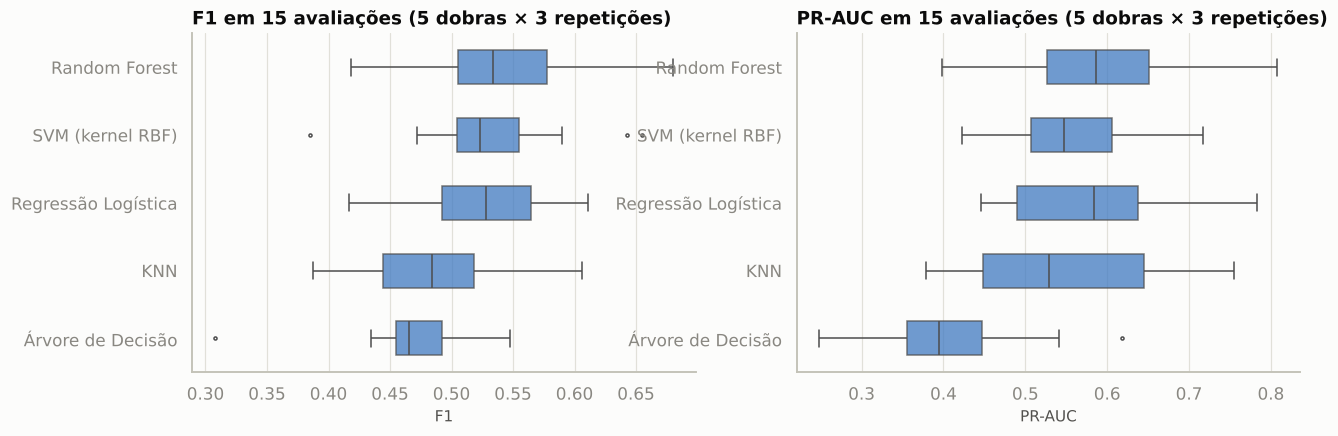

In [12]:
ordem = resumo_rep.index.tolist()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, met in zip(axes, ["F1", "PR-AUC"]):
    sns.boxplot(data=rep_df, y="modelo", x=met, order=ordem, color=viz.COLOR_HIGH, width=0.5,
                linewidth=1, fliersize=2, ax=ax, boxprops={"alpha": 0.75})
    ax.set_ylabel("")
    ax.set_title(f"{met} em 15 avaliações (5 dobras × 3 repetições)", loc="left")
viz.save_fig(fig, "11_cv_repetida")
plt.show()

**Leitura.** Com 15 avaliações, **Random Forest, Regressão Logística e SVM formam o grupo de cima**, com F1 médio
na faixa de 0,52–0,54 e PR-AUC na faixa de 0,56–0,59 — diferenças menores que o desvio-padrão. KNN e,
principalmente, a Árvore de Decisão isolada ficam atrás (a árvore única tem o pior resultado em todas as métricas).

**Modelos levados ao teste como finalistas:**
- **Random Forest** — melhor desempenho médio (modelo principal);
- **Regressão Logística** — desempenho próximo, menor variação e coeficientes interpretáveis (modelo de
  referência para explicar *o porquê*).

## 6. Avaliação no conjunto de teste

Agora, e só agora, usamos os 204 vinhos separados no início. Mostramos todos os modelos com o limiar padrão
(0,5) para comparação; a escolha de limiar é discutida na seção 7.

In [13]:
probas_teste = {nome: busca.predict_proba(X_test)[:, 1] for nome, busca in buscas.items()}
linhas = []
for nome, p in probas_teste.items():
    m = classification_metrics(y_test, p, threshold=0.5)
    linhas.append({"modelo": MODEL_NAMES[nome], **m})
teste_05 = pd.DataFrame(linhas).sort_values("pr_auc", ascending=False)
format_metrics(teste_05.drop(columns="limiar"))

,modelo,f1,recall,precision,especificidade,acuracia,acuracia_balanceada,roc_auc,pr_auc,VP,FP,FN,VN
4,Random Forest,0.571,0.667,0.500,0.898,0.868,0.782,0.909,0.688,18,18,9,159
2,SVM (kernel RBF),0.465,0.370,0.625,0.966,0.887,0.668,0.907,0.615,10,6,17,171
1,KNN,0.524,0.815,0.386,0.802,0.804,0.809,0.893,0.599,22,35,5,142
3,Árvore de Decisão,0.482,0.741,0.357,0.797,0.789,0.769,0.830,0.487,20,36,7,141
0,Regressão Logística,0.482,0.741,0.357,0.797,0.789,0.769,0.889,0.478,20,36,7,141


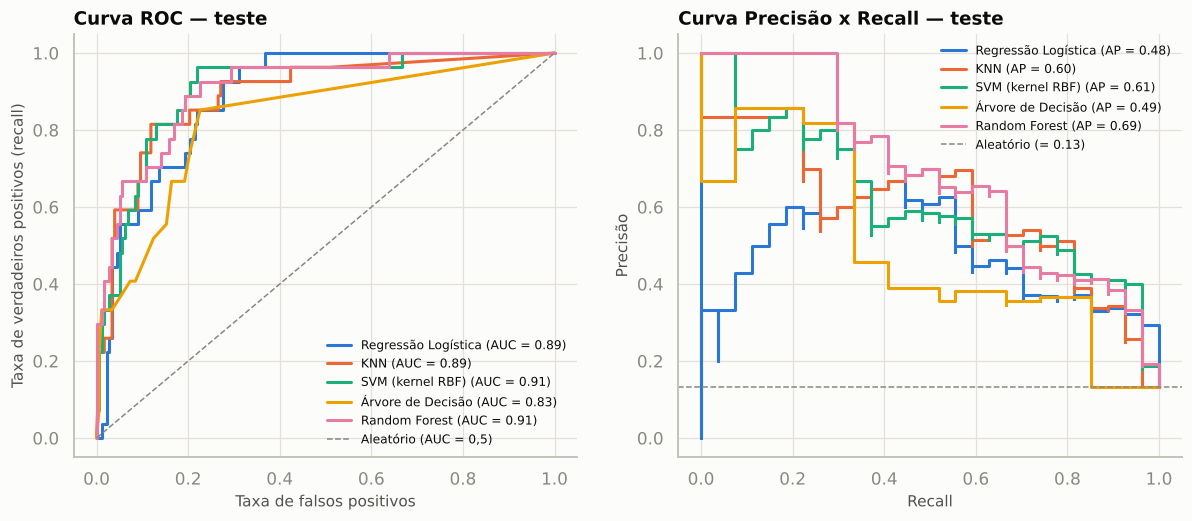

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
# curvas calculadas diretamente (compatível com qualquer versão do scikit-learn)
for (nome, p), cor in zip(probas_teste.items(), viz.MODEL_COLORS):
    fpr, tpr, _ = roc_curve(y_test, p)
    prec, rec, _ = precision_recall_curve(y_test, p)
    axes[0].plot(fpr, tpr, color=cor, linewidth=2,
                 label=f"{MODEL_NAMES[nome]} (AUC = {roc_auc_score(y_test, p):.2f})")
    axes[1].step(rec, prec, where="post", color=cor, linewidth=2,
                 label=f"{MODEL_NAMES[nome]} (AP = {average_precision_score(y_test, p):.2f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color=viz.MUTED, linewidth=1, label="Aleatório (AUC = 0,5)")
axes[0].set_title("Curva ROC — teste", loc="left")
axes[0].set_xlabel("Taxa de falsos positivos")
axes[0].set_ylabel("Taxa de verdadeiros positivos (recall)")
axes[1].axhline(y_test.mean(), linestyle="--", color=viz.MUTED, linewidth=1,
                label=f"Aleatório (= {y_test.mean():.2f})")
axes[1].set_title("Curva Precisão x Recall — teste", loc="left")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precisão")
for ax in axes:
    ax.legend(fontsize=8, loc="lower right" if ax is axes[0] else "upper right")
viz.save_fig(fig, "12_curvas_roc_pr")
plt.show()

**Leitura.**
- **Random Forest** tem a melhor capacidade de ordenar os vinhos no teste (ROC-AUC ≈ 0,91 e PR-AUC ≈ 0,69, contra
  0,13 de um classificador aleatório na curva precisão-recall), confirmando a validação cruzada.
- Com o limiar de 0,5, o SVM fica conservador (alta precisão, recall baixo) e a Regressão Logística e a Árvore
  ficam "generosas" (recall alto, precisão baixa) — por isso o limiar precisa ser escolhido de forma consciente
  (seção 7).
- A ROC-AUC de ~0,9 indica que, sorteando um vinho bom e um comum, o modelo dá nota maior ao bom em ~9 de 10
  vezes. O valor não é 1 (o que seria suspeito de vazamento, como alertado nas aulas).

## 7. Escolha do limiar de decisão

O modelo devolve uma **probabilidade** de o vinho ser de alta qualidade; o limiar transforma isso em "sim/não".
Escolhemos o limiar **no treino**, com probabilidades *fora da dobra* (cada vinho previsto por um modelo que não o
viu), maximizando o F1 — nunca olhando o teste.

In [15]:
finalistas = ["rf", "logreg"]
limiares, linhas = {}, []
for nome in finalistas:
    oof = oof_probabilities(buscas[nome].best_estimator_, X_train, y_train)
    t, f1_oof = best_f1_threshold(y_train, oof)
    limiares[nome] = {"limiar": t, "oof": oof}
    for lim, rot in [(0.5, "padrão 0,5"), (t, f"otimizado no treino ({t:.2f})")]:
        m = classification_metrics(y_test, probas_teste[nome], threshold=lim)
        linhas.append({"modelo": MODEL_NAMES[nome], "limiar": rot, **{k: m[k] for k in
                       ["f1", "recall", "precision", "especificidade", "acuracia_balanceada", "VP", "FP", "FN", "VN"]}})
comparacao_limiar = pd.DataFrame(linhas)
comparacao_limiar.to_csv(RESULTS_DIR / "metricas_teste_finalistas.csv", index=False)
format_metrics(comparacao_limiar)

,modelo,limiar,f1,recall,precision,especificidade,acuracia_balanceada,VP,FP,FN,VN
0,Random Forest,"padrão 0,5",0.571,0.667,0.500,0.898,0.782,18,18,9,159
1,Random Forest,otimizado no treino (0.43),0.559,0.704,0.463,0.876,0.790,19,22,8,155
2,Regressão Logística,"padrão 0,5",0.482,0.741,0.357,0.797,0.769,20,36,7,141
3,Regressão Logística,otimizado no treino (0.72),0.533,0.593,0.485,0.904,0.748,16,17,11,160


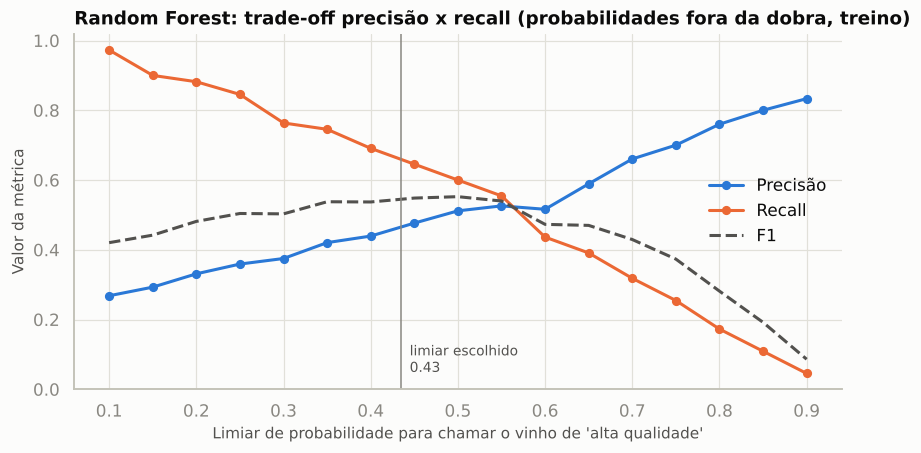

,limiar,precision,recall,f1,especificidade,VP,FP,FN,VN
0,0.10,0.27,0.97,0.42,0.59,107,292,3,412
1,0.15,0.29,0.90,0.44,0.66,99,239,11,465
2,0.20,0.33,0.88,0.48,0.72,97,196,13,508
3,0.25,0.36,0.85,0.50,0.76,93,166,17,538
4,0.30,0.38,0.76,0.50,0.80,84,140,26,564
5,0.35,0.42,0.75,0.54,0.84,82,113,28,591
6,0.40,0.44,0.69,0.54,0.86,76,97,34,607
7,0.45,0.48,0.65,0.55,0.89,71,78,39,626
8,0.50,0.51,0.60,0.55,0.91,66,63,44,641
9,0.55,0.53,0.55,0.54,0.92,61,55,49,649


In [16]:
tab = threshold_table(y_train, limiares["rf"]["oof"])
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(tab["limiar"], tab["precision"], color=viz.COLOR_HIGH, linewidth=2, marker="o", markersize=5, label="Precisão")
ax.plot(tab["limiar"], tab["recall"], color=viz.COLOR_LOW, linewidth=2, marker="o", markersize=5, label="Recall")
ax.plot(tab["limiar"], tab["f1"], color=viz.INK_2, linewidth=2, linestyle="--", label="F1")
ax.axvline(limiares["rf"]["limiar"], color=viz.MUTED, linewidth=1)
ax.text(limiares["rf"]["limiar"] + 0.01, 0.05, f"limiar escolhido\n{limiares['rf']['limiar']:.2f}", fontsize=9,
        color=viz.INK_2)
ax.set_xlabel("Limiar de probabilidade para chamar o vinho de 'alta qualidade'")
ax.set_ylabel("Valor da métrica")
ax.set_ylim(0, 1.02)
ax.set_title("Random Forest: trade-off precisão x recall (probabilidades fora da dobra, treino)", loc="left")
ax.legend(loc="center right")
viz.save_fig(fig, "13_tradeoff_limiar")
plt.show()
format_metrics(tab, 2)

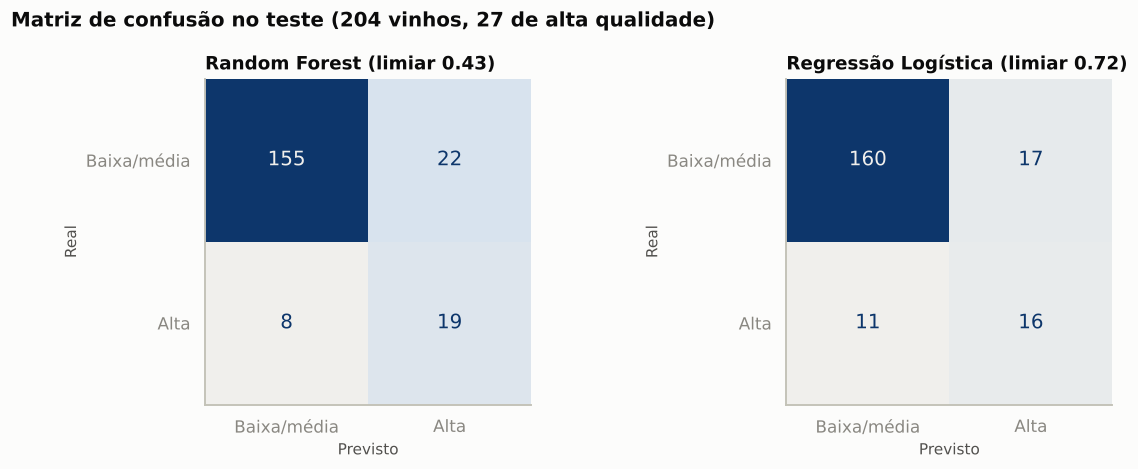

Classification report — Random Forest (limiar otimizado no treino)

              precision    recall  f1-score   support

 Baixa/média      0.951     0.876     0.912       177
        Alta      0.463     0.704     0.559        27

    accuracy                          0.853       204
   macro avg      0.707     0.790     0.735       204
weighted avg      0.886     0.853     0.865       204



In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, nome in zip(axes, finalistas):
    pred = (probas_teste[nome] >= limiares[nome]["limiar"]).astype(int)
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Baixa/média", "Alta"], cmap=viz.SEQUENTIAL, colorbar=False, ax=ax,
        text_kw={"fontsize": 13})
    ax.set_title(f"{MODEL_NAMES[nome]} (limiar {limiares[nome]['limiar']:.2f})", loc="left")
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")
    ax.grid(False)
fig.suptitle("Matriz de confusão no teste (204 vinhos, 27 de alta qualidade)", fontsize=13,
             fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
viz.save_fig(fig, "14_matriz_confusao")
plt.show()

rf_pred = (probas_teste["rf"] >= limiares["rf"]["limiar"]).astype(int)
print("Classification report — Random Forest (limiar otimizado no treino)\n")
print(classification_report(y_test, rf_pred, target_names=["Baixa/média", "Alta"], digits=3))

**Leitura e decisão.**
- O limiar escolhido no treino para a Random Forest (0,43) fica próximo de 0,5; no teste, os dois limiares dão
  resultados muito parecidos (com 0,43, o modelo acha 1 vinho bom a mais ao custo de 4 alarmes falsos a mais).
  Isso indica que as probabilidades da Random Forest já são bem comportadas e que a escolha não foi "ajustada
  ao teste".
- Para a Regressão Logística, o limiar ótimo (0,72) é bem mais alto que 0,5 (efeito do `class_weight="balanced"`, que
  empurra as probabilidades para cima): subir o limiar troca recall por precisão e melhora o F1.
- **Modelo final: Random Forest com limiar 0,43 (definido no treino).** No teste, encontra 19 dos 27 vinhos de alta
  qualidade (recall ≈ 0,70) e, quando aponta um vinho como "alta", acerta quase metade das vezes (precisão ≈ 0,46,
  contra 0,13 se apontasse ao acaso). Também reconhece corretamente ~88% dos vinhos comuns (especificidade).
  F1 no teste = 0,56, em linha com a validação cruzada (0,54–0,55).
- **O limiar é uma alavanca de negócio:** se a vinícola quiser usar o modelo como *triagem* (não perder vinho bom),
  baixa o limiar e ganha recall; se quiser usá-lo para *selo premium* (não errar o que chama de premium), sobe o
  limiar e ganha precisão. A tabela acima mostra o efeito de cada escolha.

## 8. Interpretação: o que mais influencia a qualidade

Usamos três visões complementares, para não depender de um único método:
1. **Importância por permutação** (Random Forest, no teste): quanto o desempenho cai quando "embaralhamos" uma
   variável — mede o quanto o modelo depende dela.
2. **Coeficientes da Regressão Logística** (variáveis padronizadas): direção (+/−) e força do efeito.
3. **Árvore de decisão rasa** (3 níveis): regras simples, legíveis por qualquer pessoa.

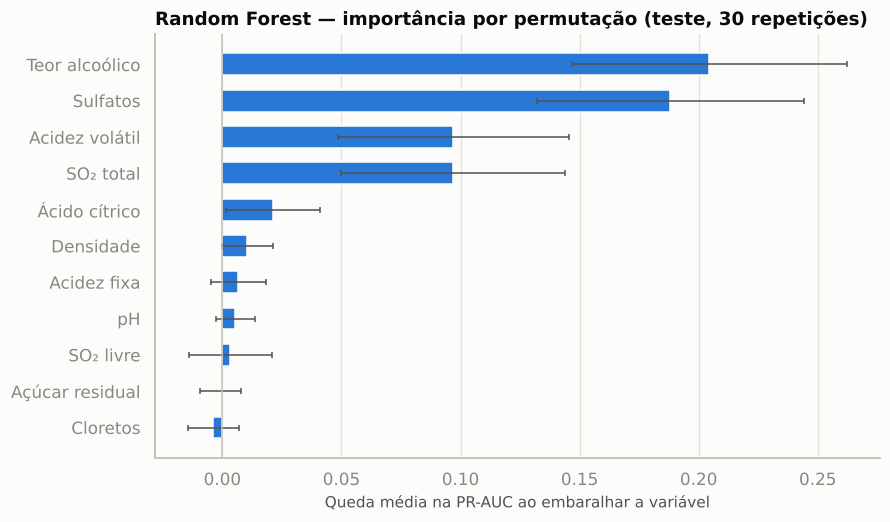

,variavel,importancia,dp
10,Teor alcoólico,0.2045,0.0577
9,Sulfatos,0.1881,0.0561
1,Acidez volátil,0.0970,0.0486
6,SO₂ total,0.0970,0.0470
2,Ácido cítrico,0.0211,0.0198
7,Densidade,0.0104,0.0107
0,Acidez fixa,0.0066,0.0116
8,pH,0.0054,0.0083
5,SO₂ livre,0.0034,0.0175
3,Açúcar residual,-0.0007,0.0087


In [18]:
perm = permutation_importance(buscas["rf"].best_estimator_, X_test, y_test, scoring="average_precision",
                              n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
imp = pd.DataFrame({"variavel": FEATURES, "importancia": perm.importances_mean, "dp": perm.importances_std})
imp = imp.sort_values("importancia")

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.barh([label(v) for v in imp["variavel"]], imp["importancia"], xerr=imp["dp"], color=viz.COLOR_HIGH,
        height=0.6, error_kw={"ecolor": viz.INK_2, "elinewidth": 1, "capsize": 2})
ax.axvline(0, color="#c3c2b7", linewidth=1)
ax.set_xlabel("Queda média na PR-AUC ao embaralhar a variável")
ax.set_title("Random Forest — importância por permutação (teste, 30 repetições)", loc="left")
ax.grid(axis="y", visible=False)
viz.save_fig(fig, "15_importancia_permutacao")
plt.show()
imp.sort_values("importancia", ascending=False).assign(variavel=lambda d: d["variavel"].map(label)).round(4)

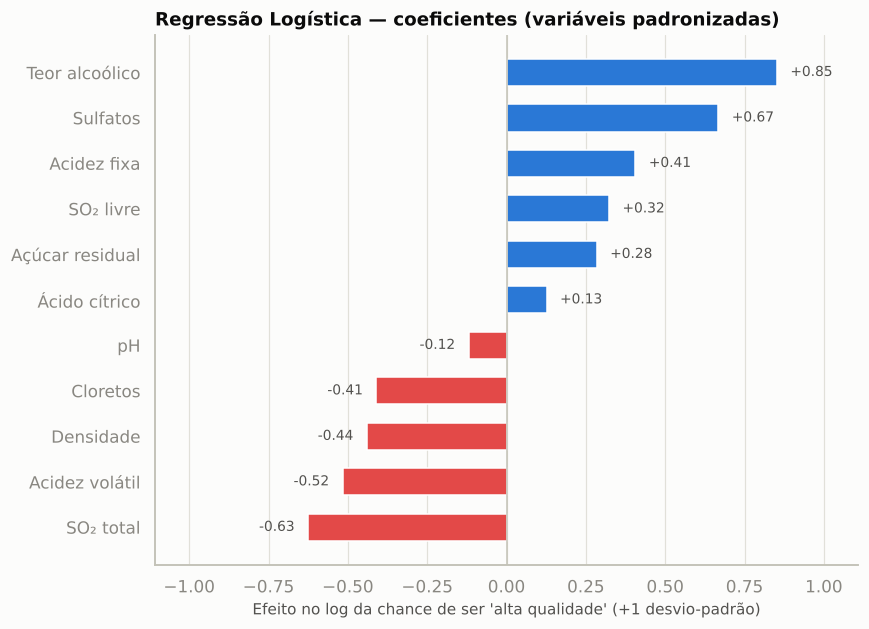

,coeficiente,razão de chances (odds ratio),transformação
SO₂ total,-0.625,0.535,log1p + z-score
Acidez volátil,-0.516,0.597,z-score
Densidade,-0.440,0.644,z-score
Cloretos,-0.410,0.664,log1p + z-score
pH,-0.119,0.888,z-score
Ácido cítrico,0.126,1.135,z-score
Açúcar residual,0.284,1.329,log1p + z-score
SO₂ livre,0.323,1.381,log1p + z-score
Acidez fixa,0.406,1.501,z-score
Sulfatos,0.667,1.949,log1p + z-score


In [19]:
lr = buscas["logreg"].best_estimator_
nomes = lr[:-1].get_feature_names_out()
coef = pd.Series(lr.named_steps["model"].coef_[0], index=nomes)
coef_tab = pd.DataFrame({
    "coeficiente": coef,
    "razão de chances (odds ratio)": np.exp(coef),
    "transformação": ["log1p + z-score" if n in SKEWED_FEATURES else "z-score" for n in nomes],
}).sort_values("coeficiente")
fig = viz.plot_bar_signed(coef, "Regressão Logística — coeficientes (variáveis padronizadas)",
                          "Efeito no log da chance de ser 'alta qualidade' (+1 desvio-padrão)")
viz.save_fig(fig, "16_coeficientes_regressao_logistica")
plt.show()
coef_tab.rename(index=label).round(3)

**Como ler os coeficientes:** com as variáveis padronizadas, o coeficiente indica o efeito de aumentar a variável
em 1 desvio-padrão, mantendo as demais fixas. A razão de chances > 1 aumenta a chance de "alta qualidade";
< 1 diminui. Como há variáveis correlacionadas (ex.: densidade, acidez fixa, pH), o coeficiente de cada uma
representa seu efeito **descontado** das outras — por isso olhamos também a importância por permutação.

Árvore rasa (3 níveis) no teste: F1 = 0.51 | recall = 0.81 | precisão = 0.37 | ROC-AUC = 0.87


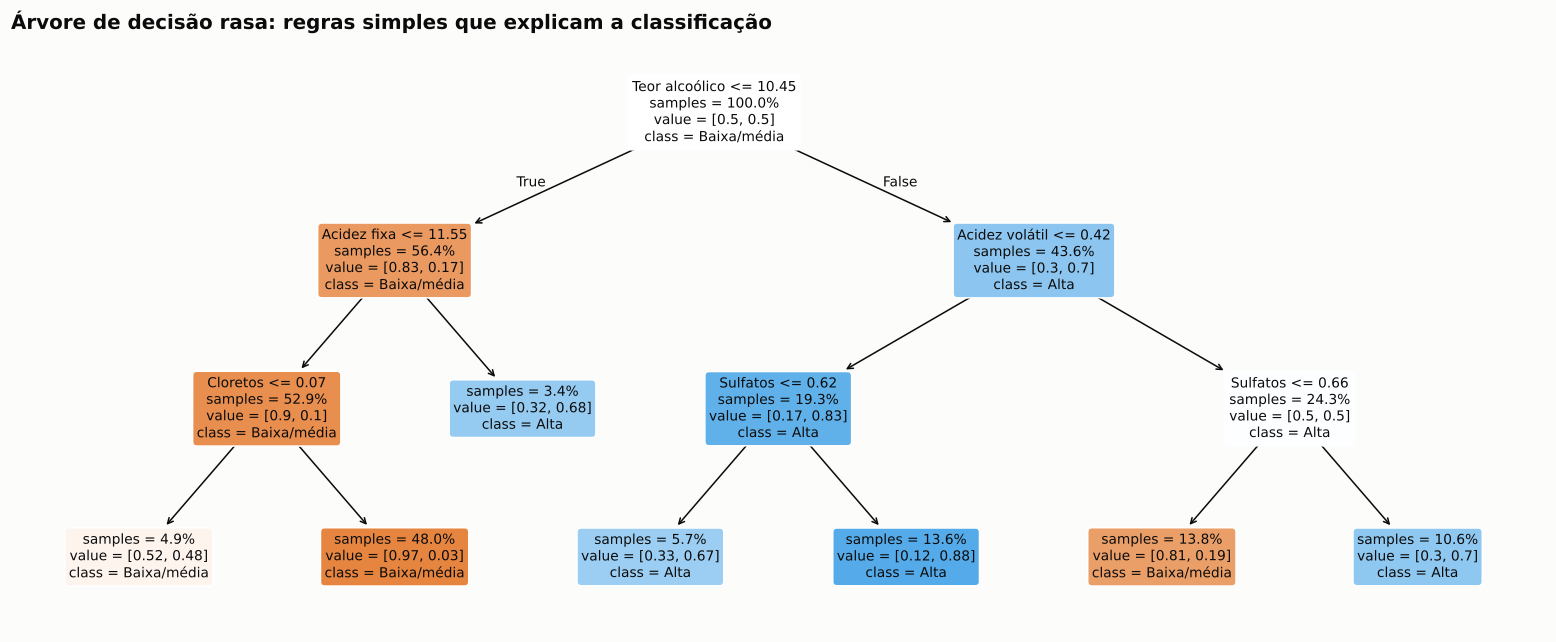

|--- Teor alcoólico <= 10.45
|   |--- Acidez fixa <= 11.55
|   |   |--- Cloretos <= 0.07
|   |   |   |--- class: 0
|   |   |--- Cloretos >  0.07
|   |   |   |--- class: 0
|   |--- Acidez fixa >  11.55
|   |   |--- class: 1
|--- Teor alcoólico >  10.45
|   |--- Acidez volátil <= 0.42
|   |   |--- Sulfatos <= 0.62
|   |   |   |--- class: 1
|   |   |--- Sulfatos >  0.62
|   |   |   |--- class: 1
|   |--- Acidez volátil >  0.42
|   |   |--- Sulfatos <= 0.66
|   |   |   |--- class: 0
|   |   |--- Sulfatos >  0.66
|   |   |   |--- class: 1



In [20]:
arvore = DecisionTreeClassifier(max_depth=3, min_samples_leaf=20, class_weight="balanced",
                                random_state=RANDOM_STATE).fit(X_train, y_train)
m_arv = classification_metrics(y_test, arvore.predict_proba(X_test)[:, 1], 0.5)
print(f"Árvore rasa (3 níveis) no teste: F1 = {m_arv['f1']:.2f} | recall = {m_arv['recall']:.2f} | "
      f"precisão = {m_arv['precision']:.2f} | ROC-AUC = {m_arv['roc_auc']:.2f}")

fig, ax = plt.subplots(figsize=(18, 7))
plot_tree(arvore, feature_names=[label(c) for c in FEATURES], class_names=["Baixa/média", "Alta"],
          filled=True, rounded=True, impurity=False, proportion=True, precision=2, fontsize=9, ax=ax)
ax.set_title("Árvore de decisão rasa: regras simples que explicam a classificação", loc="left", fontsize=13)
viz.save_fig(fig, "17_arvore_regras")
plt.show()
print(export_text(arvore, feature_names=[label(c) for c in FEATURES], decimals=2))

In [21]:
# Resumo: as três visões concordam?
ranking = pd.DataFrame({
    "permutação RF (posição)": imp.set_index("variavel")["importancia"].rank(ascending=False),
    "|coef| LR (posição)": coef.reindex(FEATURES).abs().rank(ascending=False),
    "importância árvore rasa": pd.Series(arvore.feature_importances_, index=FEATURES).round(2),
    "direção (mediana alta x baixa)": np.sign(df[df[TARGET] == 1][FEATURES].median()
                                              - df[df[TARGET] == 0][FEATURES].median()).map({1: "↑", -1: "↓", 0: "="}),
}).sort_values("permutação RF (posição)")
ranking.rename(index=label)

,permutação RF (posição),|coef| LR (posição),importância árvore rasa,direção (mediana alta x baixa)
Teor alcoólico,1.0,1.0,0.55,↑
Sulfatos,2.0,2.0,0.14,↑
Acidez volátil,3.0,4.0,0.13,↓
SO₂ total,4.0,3.0,0.00,↓
Ácido cítrico,5.0,10.0,0.00,↑
Densidade,6.0,5.0,0.00,↓
Acidez fixa,7.0,7.0,0.11,↑
pH,8.0,11.0,0.00,↓
SO₂ livre,9.0,8.0,0.00,↓
Açúcar residual,10.0,9.0,0.00,↑


**Leitura.** As três visões apontam os mesmos protagonistas:

1. **Teor alcoólico (↑)** — a variável mais importante em todas as visões: vinhos com mais álcool têm muito mais
   chance de ser de alta qualidade.
2. **Sulfatos (↑)** — segundo maior sinal: a proteção contra oxidação e micróbios preserva frescor e aroma.
3. **Acidez volátil (↓)** — o principal sinal negativo na EDA (maior efeito negativo nos testes) e na árvore: ácido
   acético (gosto/aroma de vinagre) derruba a avaliação. Na regressão, ela divide esse papel com o SO₂ total.

Logo atrás vem o **SO₂ total (↓)** — 4º na permutação e 3º na regressão: excesso de conservante está associado a
vinhos comuns. Depois, com peso menor e menos consistente entre os métodos, aparecem **densidade (↓, sobreposta ao
álcool)**, **ácido cítrico (↑)**, **acidez fixa** e **cloretos (↓)**. **Açúcar residual e pH têm pouca influência**,
o que bate com a EDA. (O SO₂ livre ganha coeficiente positivo na regressão apenas *depois de descontado o SO₂
total*: com o total fixo, mais SO₂ livre significa menos SO₂ combinado.)

A árvore rasa transforma isso em regras quase "de bolso": a primeira pergunta é o **teor alcoólico** (corte em
~10,5%); acima disso, o vinho tende a "alta" quando a **acidez volátil está abaixo de ~0,42 g/dm³** ou, se a acidez
for maior, quando os **sulfatos passam de ~0,66 g/dm³**. Com só 3 níveis, ela já encontra 81% dos vinhos bons do
teste (precisão menor, 0,37) — útil para explicar, não para substituir a Random Forest.

## 9. Implicações para o processo de produção

Lembrando: os dados são **observacionais** — mostram associação, não causa. As recomendações abaixo são hipóteses
fortes a validar com o enólogo e com testes controlados de lote.

| Achado | Implicação prática |
|---|---|
| Acidez volátil alta é o principal sinal negativo | **Controle de higiene e fermentação** (temperatura, oxigênio, contaminação por bactérias acéticas); monitorar ácido acético ao longo do processo e agir antes que passe de ~0,4 g/dm³ (corte encontrado pela árvore;
mediana dos vinhos bons = 0,36 e dos comuns = 0,55). |
| Mais teor alcoólico está associado a alta qualidade | Reflete **uvas mais maduras e fermentação completa**: ponto de colheita e acompanhamento da fermentação. Não significa "adicionar álcool". |
| Sulfatos mais altos (mediana dos vinhos bons ≈ 0,74 g/dm³ vs 0,60 nos comuns) favorecem a qualidade | Revisar o **protocolo de sulfitação/conservação**; o efeito satura — valores muito altos não ajudam. |
| SO₂ total e cloretos altos aparecem nos vinhos comuns | Evitar **excesso de SO₂** (mascara aromas) e investigar origem de sais (uva, solo, água, aditivos). |
| Ácido cítrico um pouco mais alto nos vinhos bons | Preservar frescor; também indica menor degradação bacteriana. |
| Modelo identifica ~70% dos vinhos bons com ROC-AUC ≈ 0,9 | Usar como **triagem de laboratório**: priorizar lotes promissores para a prova sensorial e sinalizar lotes de risco cedo — **apoio** ao enólogo, não substituto. |

## 10. Conclusões e limitações

**Conclusões**
- O problema é viável: com 11 medições de laboratório, o modelo separa bem vinhos de alta qualidade
  (ROC-AUC ≈ 0,9 no teste), muito acima do acaso.
- **Random Forest** foi o melhor modelo; a **Regressão Logística** ficou próxima e serve como modelo explicativo.
  Como as diferenças entre os finalistas são pequenas, a escolha também considera robustez e interpretabilidade.
- Os fatores que mais pesam são **teor alcoólico (+)**, **sulfatos (+)** e **acidez volátil (−)**.

**Limitações**
- **Base pequena e desbalanceada:** 1.018 vinhos únicos e só 27 de alta qualidade no teste — as métricas de teste
  têm incerteza alta (±1 vinho muda o recall em ~4 pontos). A validação cruzada repetida reduz esse problema, mas
  não o elimina.
- **Apenas vinho tinto de uma região (Vinho Verde, Portugal):** não generaliza automaticamente para outros tipos e
  regiões.
- **Alvo subjetivo:** a nota é a mediana de avaliações sensoriais; o modelo herda os critérios desses avaliadores.
- **Variáveis ausentes:** casta, safra, preço, tempo de barrica etc. não estão na base e certamente influenciam a
  qualidade.
- **Associação ≠ causa:** recomendações precisam ser testadas em produção.

**Próximos passos sugeridos:** coletar mais lotes de alta qualidade; testar o modelo com a base de vinhos brancos;
monitorar o desempenho do modelo ao longo das safras (os dados mudam com o tempo).

In [22]:
# Resumo final salvo em results/
final = comparacao_limiar[comparacao_limiar["limiar"].str.startswith("otimizado")].copy()
final.to_csv(RESULTS_DIR / "metricas_teste_modelo_final.csv", index=False)
teste_05.to_csv(RESULTS_DIR / "metricas_teste_todos_modelos.csv", index=False)
sorted(p.name for p in RESULTS_DIR.glob("*.csv"))

['eda_outliers.csv',
 'eda_testes_estatisticos.csv',
 'metricas_cv_repetida.csv',
 'metricas_teste_finalistas.csv',
 'metricas_teste_modelo_final.csv',
 'metricas_teste_todos_modelos.csv',
 'metricas_validacao_cruzada.csv']